# SML & BDA Experiment 4
## Title - Dimensionality Reduction using Principal Component Analysis (PCA)
### Name - Manan Chahal
### Roll No - 23102C0044

#Initialization

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession
from pyspark.ml.feature import VectorAssembler, StandardScaler, PCA

from sklearn.datasets import load_wine

In [ ]:
spark = SparkSession.builder \
    .appName("Wine_PCA_Experiment") \
    .master("local[*]") \
    .getOrCreate()

spark.sparkContext.setLogLevel("ERROR")

print("Spark Version:", spark.version)

Spark Version: 4.0.3


# Loading Dataset

In [ ]:
wine = load_wine()

X = wine.data
y = wine.target

feature_names = wine.feature_names

print("Shape:", X.shape)
print("Features:", feature_names)

Shape: (178, 13)
Features: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


In [ ]:
pdf = pd.DataFrame(X, columns=feature_names)
pdf["label"] = y

df = spark.createDataFrame(pdf)

print("Rows:", df.count())
print("Columns:", len(df.columns))

df.show(5)

Rows: 178
Columns: 14
+-------+----------+----+-----------------+---------+-------------+----------+--------------------+---------------+---------------+----+----------------------------+-------+-----+
|alcohol|malic_acid| ash|alcalinity_of_ash|magnesium|total_phenols|flavanoids|nonflavanoid_phenols|proanthocyanins|color_intensity| hue|od280/od315_of_diluted_wines|proline|label|
+-------+----------+----+-----------------+---------+-------------+----------+--------------------+---------------+---------------+----+----------------------------+-------+-----+
|  14.23|      1.71|2.43|             15.6|    127.0|          2.8|      3.06|                0.28|           2.29|           5.64|1.04|                        3.92| 1065.0|    0|
|   13.2|      1.78|2.14|             11.2|    100.0|         2.65|      2.76|                0.26|           1.28|           4.38|1.05|                         3.4| 1050.0|    0|
|  13.16|      2.36|2.67|             18.6|    101.0|          2.8|      3.24|

In [ ]:
df.printSchema()

root
 |-- alcohol: double (nullable = true)
 |-- malic_acid: double (nullable = true)
 |-- ash: double (nullable = true)
 |-- alcalinity_of_ash: double (nullable = true)
 |-- magnesium: double (nullable = true)
 |-- total_phenols: double (nullable = true)
 |-- flavanoids: double (nullable = true)
 |-- nonflavanoid_phenols: double (nullable = true)
 |-- proanthocyanins: double (nullable = true)
 |-- color_intensity: double (nullable = true)
 |-- hue: double (nullable = true)
 |-- od280/od315_of_diluted_wines: double (nullable = true)
 |-- proline: double (nullable = true)
 |-- label: long (nullable = true)



# Creating vector and standard scaling

In [ ]:
assembler = VectorAssembler(
    inputCols=feature_names,
    outputCol="features"
)

assembled_df = assembler.transform(df)

assembled_df.select("features", "label").show(5, truncate=False)

+---------------------------------------------------------------------+-----+
|features                                                             |label|
+---------------------------------------------------------------------+-----+
|[14.23,1.71,2.43,15.6,127.0,2.8,3.06,0.28,2.29,5.64,1.04,3.92,1065.0]|0    |
|[13.2,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.4,1050.0] |0    |
|[13.16,2.36,2.67,18.6,101.0,2.8,3.24,0.3,2.81,5.68,1.03,3.17,1185.0] |0    |
|[14.37,1.95,2.5,16.8,113.0,3.85,3.49,0.24,2.18,7.8,0.86,3.45,1480.0] |0    |
|[13.24,2.59,2.87,21.0,118.0,2.8,2.69,0.39,1.82,4.32,1.04,2.93,735.0] |0    |
+---------------------------------------------------------------------+-----+
only showing top 5 rows


In [ ]:
scaler = StandardScaler(
    inputCol="features",
    outputCol="scaled_features",
    withMean=True,
    withStd=True
)

scaler_model = scaler.fit(assembled_df)

scaled_df = scaler_model.transform(assembled_df)

scaled_df.select("scaled_features", "label").show(5, truncate=False)

+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-----+
|scaled_features                                                                                                                                                                                                                                                  |label|
+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-----+
|[1.5143407672921363,-0.5606682205167581,0.23139978993797794,-1.166303173639134,1.9085215072784811,0.8067217293796741,1.031908069219184,-0.6577077994784335,1.2214384526666526,0.251008784141054,0.3611584

# PCA with three components

In [ ]:
pca = PCA(
    k=3,
    inputCol="scaled_features",
    outputCol="pca_features"
)

pca_model = pca.fit(scaled_df)

pca_df = pca_model.transform(scaled_df)

pca_df.select("label", "pca_features").show(5, truncate=False)

+-----+-------------------------------------------------------------+
|label|pca_features                                                 |
+-----+-------------------------------------------------------------+
|0    |[-3.3074209742892164,-1.4394022531822905,0.1652728297819744] |
|0    |[-2.2032498134202214,0.3324550711941829,2.0207570604794918]  |
|0    |[-2.5096606947618607,-1.0282507242941943,-0.9800540552552979]|
|0    |[-3.7464971904979953,-2.7486183908585313,0.1756962242213633] |
|0    |[-1.0060704895977017,-0.8673840350754072,-2.0209872565518445]|
+-----+-------------------------------------------------------------+
only showing top 5 rows


In [ ]:
print("Original dimensions:", len(feature_names))
print("Reduced dimensions:", pca_model.pc.numCols)

Original dimensions: 13
Reduced dimensions: 3


# Vizulization using the top two features

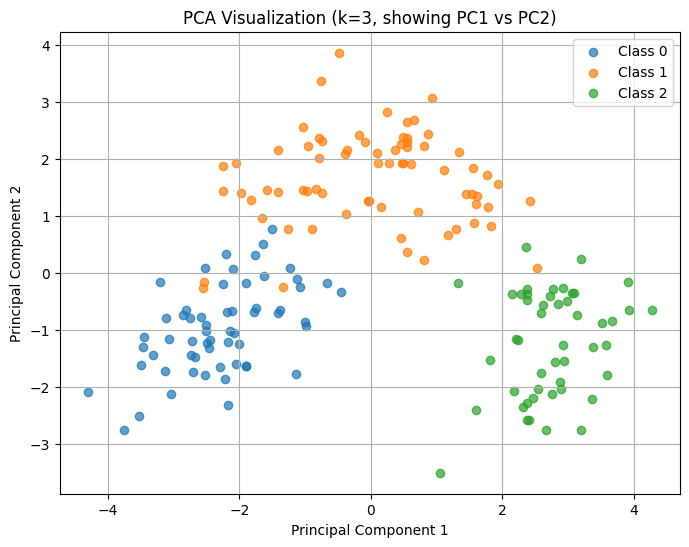

In [ ]:
plot_df = pca_df.select("label", "pca_features").toPandas()

# Extract first two principal components
plot_df["PC1"] = plot_df["pca_features"].apply(lambda x: float(x[0]))
plot_df["PC2"] = plot_df["pca_features"].apply(lambda x: float(x[1]))

# Plot
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

for label in sorted(plot_df["label"].unique()):
    subset = plot_df[plot_df["label"] == label]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"Class {label}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization (k=3, showing PC1 vs PC2)")
plt.legend()
plt.grid()

plt.show()

# Conclusion
Hence, the experiment was successfully completed by applying Principal Component Analysis (PCA) using PySpark MLlib to reduce the dimensionality of a high-dimensional dataset. The dataset was first preprocessed by constructing feature vectors and standardizing them using StandardScaler to ensure uniform scaling across all features. PCA was then applied to transform the data into a lower-dimensional space while retaining the maximum possible variance. The reduced feature set was visualized to better understand the distribution and structure of the data, and a comparison between the original and transformed feature spaces highlighted the effectiveness of dimensionality reduction. Overall, the experiment demonstrates how PCA helps simplify complex datasets, improves computational efficiency, and enhances the performance of machine learning tasks by eliminating redundancy and preserving essential information.
